In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
df=pd.read_csv('creditcard.csv')
print(df.head(10))

   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   
5   2.0 -0.425966  0.960523  1.141109 -0.168252  0.420987 -0.029728  0.476201   
6   4.0  1.229658  0.141004  0.045371  1.202613  0.191881  0.272708 -0.005159   
7   7.0 -0.644269  1.417964  1.074380 -0.492199  0.948934  0.428118  1.120631   
8   7.0 -0.894286  0.286157 -0.113192 -0.271526  2.669599  3.721818  0.370145   
9   9.0 -0.338262  1.119593  1.044367 -0.222187  0.499361 -0.246761  0.651583   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -

In [3]:
df['log_amount']=np.log1p(df['Amount'])

In [4]:
print(df[["log_amount","Amount"]].head(10))

   log_amount  Amount
0    5.014760  149.62
1    1.305626    2.69
2    5.939276  378.66
3    4.824306  123.50
4    4.262539   69.99
5    1.541159    3.67
6    1.790091    4.99
7    3.732896   40.80
8    4.545420   93.20
9    1.543298    3.68


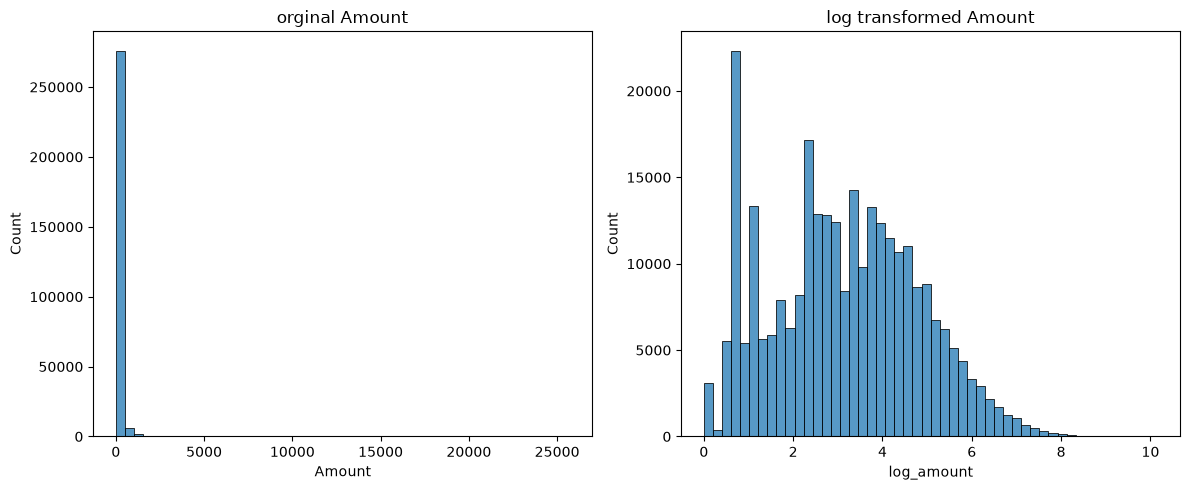

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
sns.histplot(df['Amount'], bins=50)
plt.title('orginal Amount')
plt.subplot(1,2,2)
df['log_amount'] = np.log1p(df['Amount'])
sns.histplot(df['log_amount'], bins=50)
plt.title('log transformed Amount')
plt.tight_layout()
plt.show()

In [6]:
df['log_amount']= np.log1p(df['Amount'])
print("original statistical amount:",df['Amount'].describe())
print("log-transformed amount:",df['log_amount'].describe())

original statistical amount: count    284807.000000
mean         88.349619
std         250.120109
min           0.000000
25%           5.600000
50%          22.000000
75%          77.165000
max       25691.160000
Name: Amount, dtype: float64
log-transformed amount: count    284807.000000
mean          3.152188
std           1.656648
min           0.000000
25%           1.887070
50%           3.135494
75%           4.358822
max          10.153941
Name: log_amount, dtype: float64


In [7]:
amount_skewness=df['Amount'].skew()
logamount_skewness=df['log_amount'].skew()
print("skewness of original amount:",amount_skewness)
print("skewness of log transformed amount:",logamount_skewness)

skewness of original amount: 16.977724453761006
skewness of log transformed amount: 0.16270292774164008


In [8]:
print('misssing values:',df.isna().sum())
print("missing values for log_amount:",df['log_amount'].isnull().sum())

misssing values: Time          0
V1            0
V2            0
V3            0
V4            0
V5            0
V6            0
V7            0
V8            0
V9            0
V10           0
V11           0
V12           0
V13           0
V14           0
V15           0
V16           0
V17           0
V18           0
V19           0
V20           0
V21           0
V22           0
V23           0
V24           0
V25           0
V26           0
V27           0
V28           0
Amount        0
Class         0
log_amount    0
dtype: int64
missing values for log_amount: 0


In [9]:
print("infinite values in Amount:",np.isinf(df[['Amount','log_amount']]).sum())
print("finite values in Amount:",np.isfinite(df[['Amount','log_amount']]).sum())

infinite values in Amount: Amount        0
log_amount    0
dtype: int64
finite values in Amount: Amount        284807
log_amount    284807
dtype: int64


In [10]:
expected_log_amount = np.log1p(df["Amount"])

matches = np.isclose(
    df["log_amount"],
    expected_log_amount,
    equal_nan=True
)

print("All values match the expected transformation:", matches.all())

All values match the expected transformation: True


In [11]:
comparsion=pd.DataFrame({
    "Features":["Amount","log_amount"],
    "mean":[
        df['Amount'].mean(),
        df['log_amount'].mean()
    ],
    "median":[
        df['Amount'].median(),
        df['log_amount'].median()
    ],
    "standard deviation":[
        df['Amount'].std(), 
        df['log_amount'].std()
    ],
    "skewness":[
        df['Amount'].skew(),
        df['log_amount'].skew()
    ]
})
print(comparsion.round(4))

     Features     mean   median  standard deviation  skewness
0      Amount  88.3496  22.0000            250.1201   16.9777
1  log_amount   3.1522   3.1355              1.6566    0.1627


In [12]:
print("Amount exists:", "Amount" in df.columns)
print("Log_Amount exists:", "Log_Amount" in df.columns)
print("\nSelected feature preview:")
print(df[["Amount", "log_amount"]].head(20))

Amount exists: True
Log_Amount exists: False

Selected feature preview:
    Amount  log_amount
0   149.62    5.014760
1     2.69    1.305626
2   378.66    5.939276
3   123.50    4.824306
4    69.99    4.262539
5     3.67    1.541159
6     4.99    1.790091
7    40.80    3.732896
8    93.20    4.545420
9     3.68    1.543298
10    7.80    2.174752
11    9.99    2.396986
12  121.50    4.808111
13   27.50    3.349904
14   58.80    4.091006
15   15.99    2.832625
16   12.99    2.638343
17    0.89    0.636577
18   46.80    3.867026
19    5.00    1.791759


In [13]:
print(df['Amount'].max()-1)

25690.16


In [14]:
print(df['Amount'].max())

25691.16


In [15]:
print(df['Amount'].tail(5))

284802      0.77
284803     24.79
284804     67.88
284805     10.00
284806    217.00
Name: Amount, dtype: float64


In [16]:
print("shape of dataset:",df.shape)

shape of dataset: (284807, 32)


In [17]:
print("shape of dataset:",df.shape[0],df.shape[1])

shape of dataset: 284807 32


In [18]:
missing_counts=df.isna().sum()
print("missing values in each column:\n",missing_counts.sum())

missing values in each column:
 0


In [19]:
numeric_df=df.select_dtypes(include=[np.number])
infinite_counts = np.isinf(numeric_df).sum()
print("infinite values in each column:\n",infinite_counts.sum())

infinite values in each column:
 0


In [20]:
print(infinite_counts[infinite_counts > 0])

print("\nTotal infinite values:", infinite_counts.sum())

Series([], dtype: int64)

Total infinite values: 0


In [21]:
# 4. Validate Log_Amount
print("\n=== FEATURE VALIDATION ===")
if {"Amount", "log_amount"}.issubset(df.columns):
    expected = np.log1p(df["Amount"])
    matches = np.isclose(
        df["log_amount"],
        expected,
        equal_nan=True
    )
    print("Log_Amount matches formula:", matches.all())
else:
    print("Amount or Log_Amount is missing.")

# 5. Data types
print("\n=== DATA TYPES ===")
print(df[["Amount", "log_amount"]].dtypes)


=== FEATURE VALIDATION ===
Log_Amount matches formula: True

=== DATA TYPES ===
Amount        float64
log_amount    float64
dtype: object


In [22]:
print("\n=== FEATURE VALIDATION ===")

if {"Amount", "Log_Amount"}.issubset(df.columns):
    expected = np.log1p(df["Amount"])

    matches = np.isclose(
        df["Log_Amount"],
        expected,
        equal_nan=True
    )

    print("Log_Amount matches formula:", matches.all())
else:
    print("Amount or Log_Amount is missing.")


=== FEATURE VALIDATION ===
Amount or Log_Amount is missing.


In [23]:
feature_corr=df[['Amount','log_amount']].corr()
print("feature_correlation matrix is:",feature_corr)

feature_correlation matrix is:               Amount  log_amount
Amount      1.000000    0.552005
log_amount  0.552005    1.000000


<Axes: >

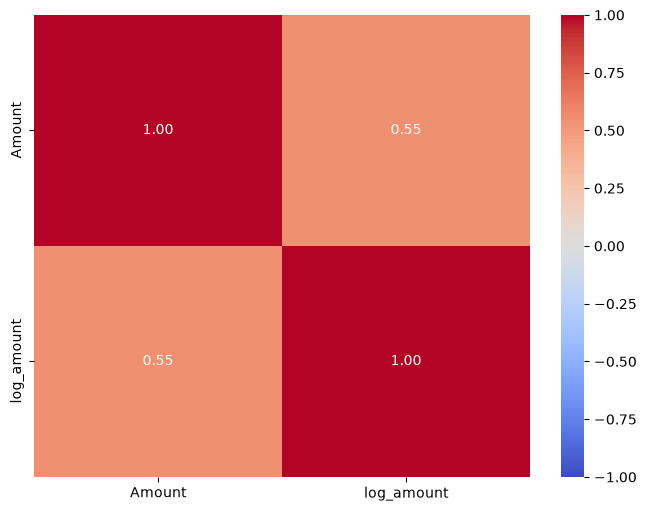

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
feature_corr=df[['Amount','log_amount']].corr()
plt.figure(figsize=(8,6))
sns.heatmap(feature_corr, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)

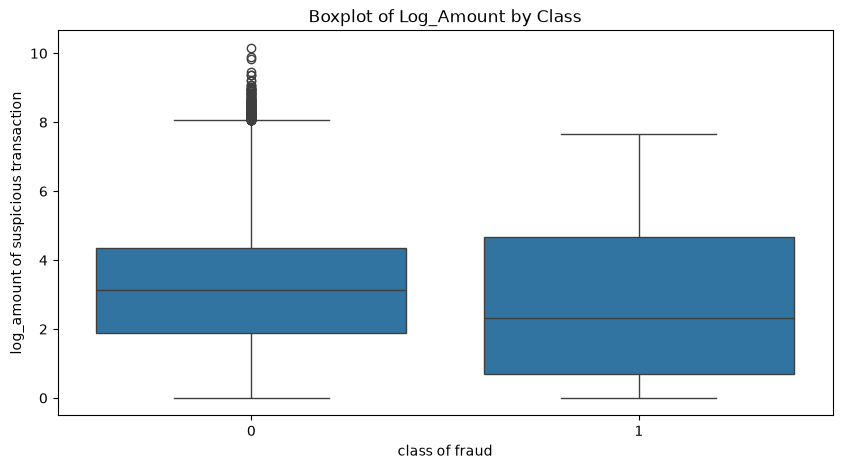

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(10,5))
sns.boxplot(
    x='Class',
    y='log_amount',
    data=df
)
plt.title('Boxplot of Log_Amount by Class')
plt.xlabel("class of fraud")
plt.ylabel("log_amount of suspicious transaction")
plt.show()

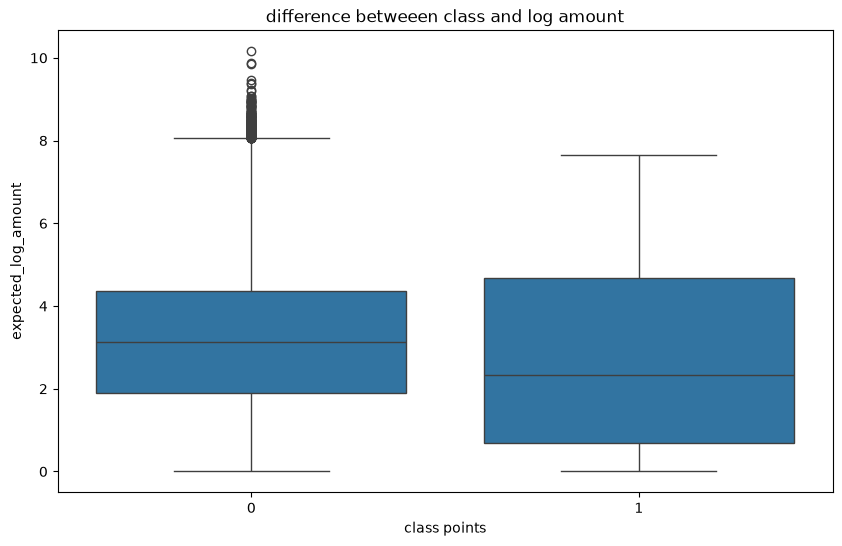

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(10,6))
sns.boxplot(
    data=df,
    x='Class',
    y='log_amount'
)
plt.title("difference betweeen class and log amount")
plt.xlabel('class points')
plt.ylabel("expected_log_amount")
plt.show()

In [27]:
import numpy as np
if {"Amount", "Log_Amount"}.issubset(df.columns):
    expected = np.log1p(df["Amount"])
    is_valid = np.allclose(
        df["Log_Amount"],
        expected,
        equal_nan=True
    )

    print("Log_Amount validation:", is_valid)
else:
    print("Required columns are missing.")

Required columns are missing.


----feature comparsion-----
              Amount     log_amount
count  284807.000000  284807.000000
mean       88.349619       3.152188
std       250.120109       1.656648
min         0.000000       0.000000
25%         5.600000       1.887070
50%        22.000000       3.135494
75%        77.165000       4.358822
max     25691.160000      10.153941


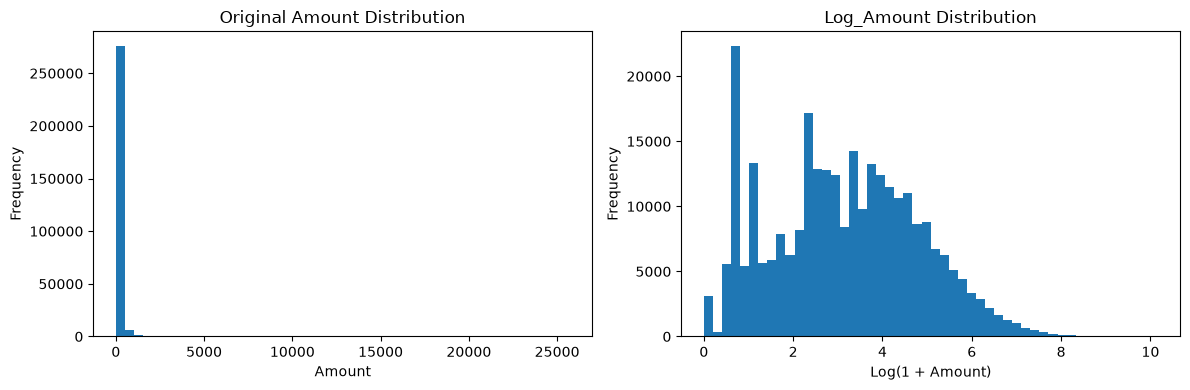

In [28]:
import matplotlib.pyplot as plt
import pandas as pd
print("----feature comparsion-----")
print(df[['Amount','log_amount']].describe())
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].hist(df["Amount"].dropna(), bins=50)
axes[0].set_title("Original Amount Distribution")
axes[0].set_xlabel("Amount")
axes[0].set_ylabel("Frequency")
axes[1].hist(df["log_amount"].dropna(), bins=50)
axes[1].set_title("Log_Amount Distribution")
axes[1].set_xlabel("Log(1 + Amount)")
axes[1].set_ylabel("Frequency")
plt.tight_layout()
plt.show()

In [29]:
print("comparsion of skewness")
amount_skewness=df['Amount'].skew()
log_amount_skewness=df['log_amount'].skew()
print("orginial amount of skewness:",amount_skewness)
print("log amount of skewness:",log_amount_skewness)
if abs(amount_skewness) > abs(log_amount_skewness):
     print("log transaction is transformed")
else:
    print("original amount is transformed")


comparsion of skewness
orginial amount of skewness: 16.977724453761006
log amount of skewness: 0.16270292774164008
log transaction is transformed


In [30]:
import numpy as np

print("=== LOG_AMOUNT QUALITY CHECK ===")

print("Missing values:", df["log_amount"].isna().sum())

print("Positive infinity:",
      np.isposinf(df["log_amount"]).sum())

print("Negative infinity:",
      np.isneginf(df["log_amount"]).sum())

print("Negative values:",
      (df["log_amount"] < 0).sum())

print("Zero values:",
      (df["log_amount"] == 0).sum())

=== LOG_AMOUNT QUALITY CHECK ===
Missing values: 0
Positive infinity: 0
Negative infinity: 0
Negative values: 0
Zero values: 1825


In [31]:
required_columns={'Amount','log_amount'}
if required_columns.issubset(df.columns):
    print("\nOriginal and transformed values:")
    print(df[["Amount", "log_amount"]].head())
    print("dataset shape:",df.shape)
    print("Missing values in log_amount:", df["log_amount"].isna().sum())
else:
    print("final feature review")


Original and transformed values:
   Amount  log_amount
0  149.62    5.014760
1    2.69    1.305626
2  378.66    5.939276
3  123.50    4.824306
4   69.99    4.262539
dataset shape: (284807, 32)
Missing values in log_amount: 0


In [32]:
print(" feature engineering")
required_features={'Amount','log_amount'}
if required_features.issubset(df.columns):
    print("Pass: required feature exists ")
else:
    print("Fail:required feature doesnt exists")    
print("dataset shape:",df.shape)
print("datatype of log amount:",df['log_amount'].dtype)

 feature engineering
Pass: required feature exists 
dataset shape: (284807, 32)
datatype of log amount: float64


In [33]:
missing_count = df["log_amount"].isna().sum()
print("Missing values:", missing_count)

Missing values: 0


In [34]:
expected_values = np.log1p(df["Amount"])

transformation_check = np.isclose(
    df["log_amount"],
    expected_values,
    equal_nan=True
)

print(
    "Transformation mismatches:",
    (~transformation_check).sum()
)

Transformation mismatches: 0


In [35]:
correlation_matrix=df[
    ["Amount","log_amount","Class"]
    ].corr()
print(correlation_matrix)


              Amount  log_amount     Class
Amount      1.000000    0.552005  0.005632
log_amount  0.552005    1.000000 -0.008326
Class       0.005632   -0.008326  1.000000


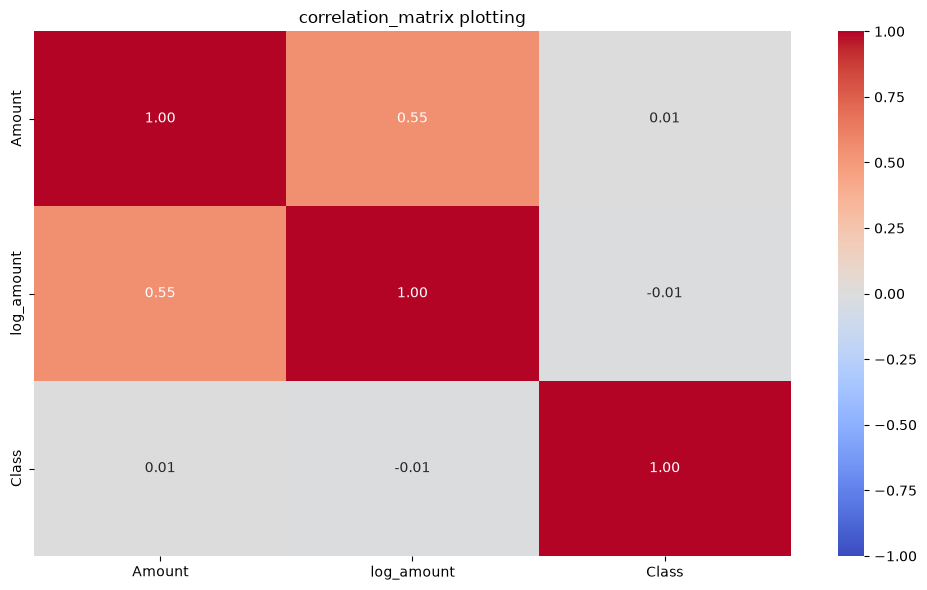

In [36]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(10,6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    vmax=1,
    vmin=-1,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("correlation_matrix plotting")
plt.tight_layout()
plt.show()

In [37]:
amount_skewness = df["Amount"].skew()

amount_skewness = df["Amount"].skew()
log_amount_skewness = df["log_amount"].skew()

print("Amount skewness:", amount_skewness)
print("Log_Amount skewness:", log_amount_skewness)

if abs(log_amount_skewness) < abs(amount_skewness):
    print("Log transformation reduced skewness.")
elif abs(log_amount_skewness) > abs(amount_skewness):
    print("Log transformation increased skewness.")
else:
    print("=== STEP 17: SKEWNESS COMPARISON ===")

    amount_skewness = df["Amount"].skew()
    log_amount_skewness = df["log_amount"].skew()

    print("Amount skewness:", amount_skewness)
    print("Log amount skewness:", log_amount_skewness)

    if abs(log_amount_skewness) < abs(amount_skewness):
        print("Log transformation reduced skewness.")
    elif abs(log_amount_skewness) > abs(amount_skewness):
        print("Log transformation increased skewness.")
    else:
        print("Absolute skewness remained the same.")
log_amount_skewness = df["log_amount"].skew()

# 17.3 Display results
print("Amount skewness:", amount_skewness)
print("Log_Amount skewness:", log_amount_skewness)

# 17.4 Compare absolute skewness
if abs(log_amount_skewness) < abs(amount_skewness):
    print("Log transformation reduced skewness.")
elif abs(log_amount_skewness) > abs(amount_skewness):
    print("Log transformation increased skewness.")
else:
    print("Absolute skewness remained the same.")


Amount skewness: 16.977724453761006
Log_Amount skewness: 0.16270292774164008
Log transformation reduced skewness.
Amount skewness: 16.977724453761006
Log_Amount skewness: 0.16270292774164008
Log transformation reduced skewness.


Text(0, 0.5, 'Frequency')

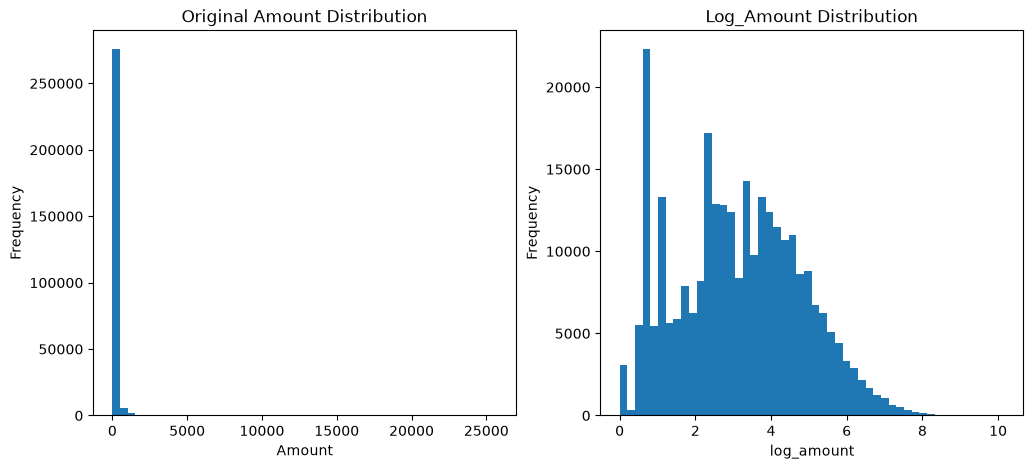

In [38]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].hist(df["Amount"].dropna(), bins=50)
axes[0].set_title("Original Amount Distribution")
axes[0].set_xlabel("Amount")
axes[0].set_ylabel("Frequency")
axes[1].hist(df["log_amount"].dropna(), bins=50)
axes[1].set_title("Log_Amount Distribution")
axes[1].set_xlabel("log_amount")
axes[1].set_ylabel("Frequency")

In [39]:
print("===comparsion of applying skewness before and after====")
amount_skewness = df["Amount"].skew()
log_amount_skewness = df["log_amount"].skew()
print("Amount skewness:", amount_skewness)
print("Log amount skewness:", log_amount_skewness)
if abs(log_amount_skewness) < abs(amount_skewness):
        print("Log transformation reduced skewness.")
elif abs(log_amount_skewness) > abs(amount_skewness):
        print("Log transformation increased skewness.")
else:
        print("Absolute skewness remained the same.")

===comparsion of applying skewness before and after====
Amount skewness: 16.977724453761006
Log amount skewness: 0.16270292774164008
Log transformation reduced skewness.


In [41]:
import numpy as np

print("=== TRANSFORMATION VALIDATION ===")

# 1. Check a few original and transformed values
comparison = df[["Amount", "log_amount"]].head(10)
print(comparison)

# 2. Calculate the expected transformed values
expected = np.log1p(df["Amount"])

# 3. Check whether Log_Amount matches the expected values
matches = np.allclose(
    df["log_amount"],
    expected,
    equal_nan=True
)

print("\nTransformation correct:", matches)

# 4. Compare skewness before and after transformation
print("\nOriginal Amount skewness:", df["Amount"].skew())
print("Log_Amount skewness:", df["log_amount"].skew())

# 5. Check whether the values actually differ
changed = ~np.isclose(
    df["Amount"],
    df["log_amount"],
    equal_nan=True
)

print("\nRows where values changed:", changed.sum())
print("Total rows:", len(df))

=== TRANSFORMATION VALIDATION ===
   Amount  log_amount
0  149.62    5.014760
1    2.69    1.305626
2  378.66    5.939276
3  123.50    4.824306
4   69.99    4.262539
5    3.67    1.541159
6    4.99    1.790091
7   40.80    3.732896
8   93.20    4.545420
9    3.68    1.543298

Transformation correct: True

Original Amount skewness: 16.977724453761006
Log_Amount skewness: 0.16270292774164008

Rows where values changed: 282982
Total rows: 284807
